# Task 1: Fake news classifier (Fakeddit, text + metadata)

Binary classification of Reddit posts from the Fakeddit dataset into **fake (0)** and **real (1)** using the post title and three engagement features.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from pathlib import Path
from sklearn.compose import ColumnTransformer  # ColumnTransformer: tekstui viena apdorojima, skaiciams kita, o rezultata sujungia i viena matrica
from sklearn.pipeline import Pipeline, make_pipeline  # Pipeline grandine: visi zingsniai mokomi tik is train, todel test duomenys niekur 'neprasisunkia'
from sklearn.impute import SimpleImputer  # SimpleImputer uzpildo NaN, nes LogisticRegression su tusciomis reiksmemis tiesiog nulus
from sklearn.preprocessing import FunctionTransformer, StandardScaler  # FunctionTransformer bet kokia numpy funkcija pavercia pipeline zingsniu, StandardScaler sucentruoja i vidurki 0 ir std 1
from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF: zodis svarbus, jei daznas sioje antrasteje, bet retas visose kitose
from sklearn.linear_model import LogisticRegression  # logistine regresija: kiekvienas zodis gauna svori, suma per sigmoid tampa tikimybe 0..1
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay  # accuracy tik bendras procentas, todel dar ziurim precision/recall kiekvienai klasei

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")  # multimodal dalis: tik irasai su paveiksleliu
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)  # grafikai iskart saugomi ataskaitai, exist_ok=True: nekrenta, jei aplankas jau yra
SEED = 42  # fiksuotas seed: atsitiktine imtis kiekviena karta bus ta pati, rezultatai atkartojami

## 1. Load data
Only the columns we need, to keep memory low. `subreddit` is loaded for exploration only.

In [2]:
COLS = ["clean_title", "score", "num_comments", "upvote_ratio", "subreddit", "2_way_label"]  # usecols: is 16 stulpeliu imam 6, kitaip 564k eiluciu su URL ir ID suvalgytu daug RAM
train_full = pd.read_csv(DATA / "multimodal_train.tsv", sep="\t", usecols=COLS)  # oficialus Fakeddit train failas, TSV = stulpeliai atskirti tabuliacija
test_full = pd.read_csv(DATA / "multimodal_test_public.tsv", sep="\t", usecols=COLS)  # oficialus test failas: atskiri irasai, todel testas nepersidengia su mokymu
train_full.shape, test_full.shape

((564000, 6), (59319, 6))

## 2. Exploration

In [3]:
print(train_full["2_way_label"].map({0: "fake", 1: "real"}).value_counts(normalize=True).round(3))  # klasiu santykis apie 61/39: jei modelis visada sakytu 'fake', jau gautu ~61% accuracy
print()
print("Missing values:"); print(train_full.isna().sum())  # NaN kiekis kiekviename stulpelyje: lemia, ar reikes imputacijos

2_way_label
fake    0.606
real    0.394
Name: proportion, dtype: float64

Missing values:
clean_title          0
num_comments    167857
score                0
subreddit            0
upvote_ratio    167857
2_way_label          0
dtype: int64


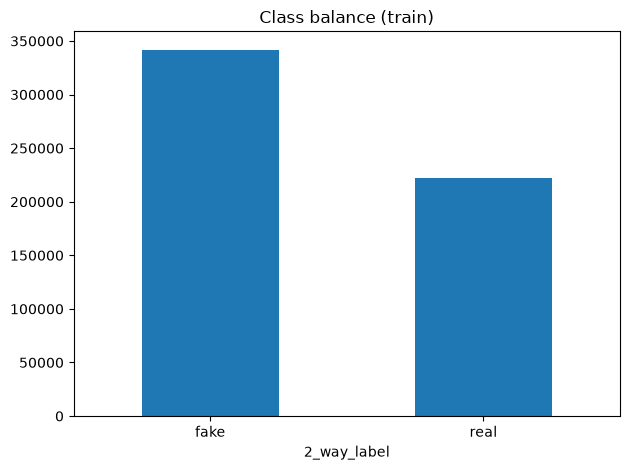

In [4]:
ax = train_full["2_way_label"].map({0: "fake", 1: "real"}).value_counts().plot.bar(rot=0, title="Class balance (train)")
plt.tight_layout(); plt.savefig(FIG / "class_balance.png", dpi=120); plt.show()

                count  mean  std  min  25%  50%   75%    max
2_way_label                                                 
0            341919.0   6.2  5.3  1.0  2.0  5.0   8.0  553.0
1            222081.0   9.5  5.6  1.0  6.0  9.0  12.0   66.0


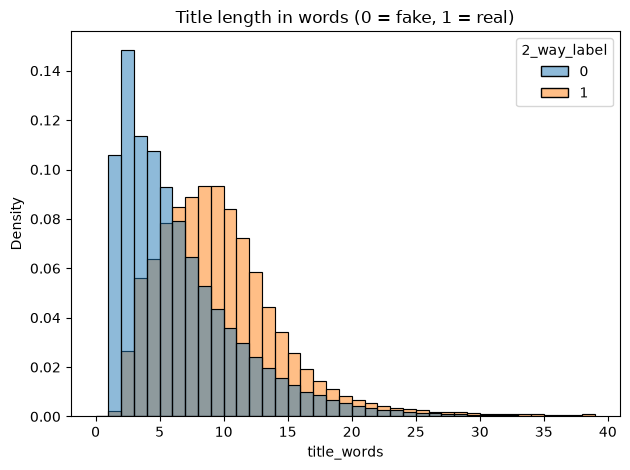

In [5]:
train_full["title_words"] = train_full["clean_title"].str.split().str.len()  # antrastes ilgis zodziais (split skaido per tarpus)
print(train_full.groupby("2_way_label")["title_words"].describe().round(1))  # fake antrastes vidutiniskai trumpesnes: daug ju yra tiesiog trumpi paveiksleliu aprasai
sns.histplot(data=train_full, x="title_words", hue="2_way_label", bins=range(0, 40), stat="density", common_norm=False)  # density + common_norm=False: abi klases normuojamos atskirai, nes ju dydziai skiriasi
plt.title("Title length in words (0 = fake, 1 = real)"); plt.tight_layout(); plt.savefig(FIG / "title_length.png", dpi=120); plt.show()

In [6]:
sub = train_full.groupby("subreddit")["2_way_label"].agg(posts="size", share_real="mean").sort_values("posts", ascending=False)  # share_real = label vidurkis (1 = real), todel 0 reiskia visi fake, 1 visi real
sub

,posts,share_real
subreddit,,
psbattle_artwork,167857,0.0
mildlyinteresting,86237,1.0
photoshopbattles,55198,1.0
pareidolia,47331,0.0
fakehistoryporn,35576,0.0
nottheonion,31977,1.0
upliftingnews,23960,1.0
fakealbumcovers,21725,0.0
misleadingthumbnails,15962,0.0


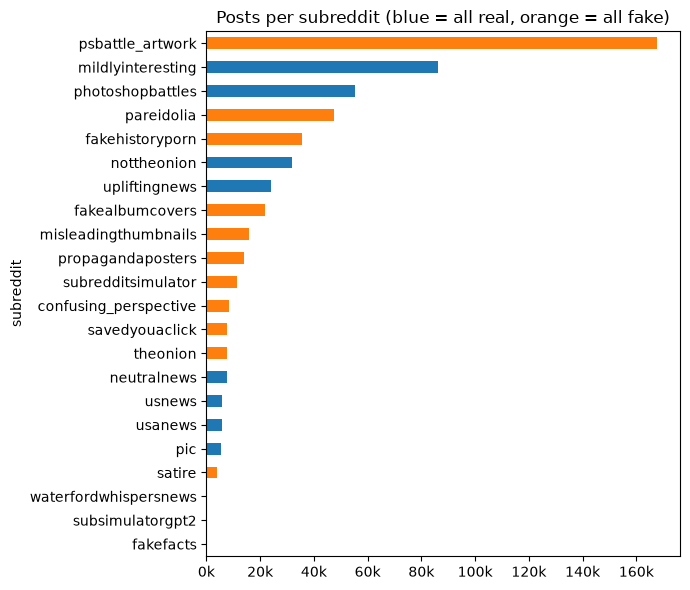

In [7]:
ax = sub["posts"].plot.barh(figsize=(7, 6), color=np.where(sub["share_real"] == 1, "tab:blue", "tab:orange"))  # spalva pagal klase: matosi, kad label nustato vien subreddit
ax.invert_yaxis(); ax.xaxis.set_major_formatter(lambda x, _: f"{x / 1000:.0f}k"); ax.set_title("Posts per subreddit (blue = all real, orange = all fake)")  # x asis tukstanciais (20k), kad ilgi skaiciai nesusilietu
plt.tight_layout(); plt.savefig(FIG / "subreddits.png", dpi=120); plt.show()

Every subreddit is 100% fake or 100% real, because Fakeddit labels posts by the subreddit they come from. Using `subreddit` as a feature would leak the label, so it is dropped.

In [8]:
miss = train_full["num_comments"].isna()  # tos pacios eilutes neturi ir upvote_ratio, tad uztenka tikrinti viena stulpeli
print("Rows with missing num_comments/upvote_ratio:", miss.sum())
print(train_full.loc[miss, "subreddit"].value_counts())  # visos jos is vieno fake subreddit: pats NaN faktas jau duoda uzuomina apie klase

Rows with missing num_comments/upvote_ratio: 167857
subreddit
psbattle_artwork    167857
Name: count, dtype: int64


The missing engagement values all come from one fake subreddit (`psbattle_artwork`). They are filled with the median, but this is a known weak spot: missingness is itself correlated with the label.

## 3. Sampling and features
* Random sample: 40,000 training rows and 10,000 test rows (from the official public test split).
* Dropped: `subreddit` (label leak), `author`, `id`, `image_url` (identifiers, not content).
* `clean_title` -> TF-IDF (unigrams + bigrams).
* `score`, `num_comments`, `upvote_ratio` -> median imputation, clip negatives to 0, `log1p`, standard scaling.

In [9]:
train = train_full.sample(40_000, random_state=SEED)  # 40k: pakanka tiesiniam modeliui ir telpa i RAM
test = test_full.sample(10_000, random_state=SEED)  # 10k: pakankamai, kad metrikos butu stabilios
del train_full, test_full
FEATURES = ["clean_title", "score", "num_comments", "upvote_ratio"]  # subreddit samoningai nera: jis 100% nusako label, modelis tiesiog nusirasytu atsakyma
X_train, y_train = train[FEATURES], train["2_way_label"]
X_test, y_test = test[FEATURES], test["2_way_label"]
print("min score:", X_train["score"].min())  # score gali buti neigiamas (daugiau downvote), o log1p neigiamiems skaiciams netinka

min score: -236


In [10]:
numeric = make_pipeline(SimpleImputer(strategy="median"),  # NaN keiciam mediana, nes ji neiskreipiama milziniu reiksmiu kaip vidurkis
                        FunctionTransformer(np.clip, kw_args={"a_min": 0, "a_max": None}, feature_names_out="one-to-one"),  # neigiamus score nukerpam iki 0, kad log1p neduotu NaN
                        FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler())  # log(1+x) suspaudzia uodega (score iki 137k, mediana 14), tada StandardScaler sulygina mastelius
features = ColumnTransformer([
    ("title", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True, stop_words="english"), "clean_title"),  # 1-2 zodziu frazes, min_df=2 ismeta vienkartinius zodzius, sublinear_tf mazina pasikartojimu itaka
    ("meta", numeric, ["score", "num_comments", "upvote_ratio"]),
])
model = Pipeline([("features", features), ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])  # class_weight='balanced': klaida su retesne klase (real) kainuoja daugiau, kad modelis jos neignoruotu

## 4. Train

In [11]:
model.fit(X_train, y_train)  # TF-IDF zodynas, medianos ir svoriai ismokstami tik is train
print("TF-IDF vocabulary size:", len(model.named_steps["features"].named_transformers_["title"].vocabulary_))  # kiek zodziu ir fraziu liko po min_df filtro

TF-IDF vocabulary size: 22155


## 5. Evaluate

In [12]:
pred = model.predict(X_test)  # tikimybe > 0.5 reiskia real, kitaip fake
print("Majority-class baseline accuracy:", round((y_test == 0).mean(), 4))  # baseline: visada spek 'fake'. Modelis turi buti aiskiai geresnis uz si skaiciu
print("Model accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["fake", "real"], digits=4))  # precision: kiek spetu teisingi; recall: kiek tikru atveju rasta; F1: ju balansas

Majority-class baseline accuracy: 0.6071
Model accuracy: 0.8145
              precision    recall  f1-score   support

        fake     0.8628    0.8257    0.8439      6071
        real     0.7475    0.7971    0.7715      3929

    accuracy                         0.8145     10000
   macro avg     0.8052    0.8114    0.8077     10000
weighted avg     0.8175    0.8145    0.8154     10000



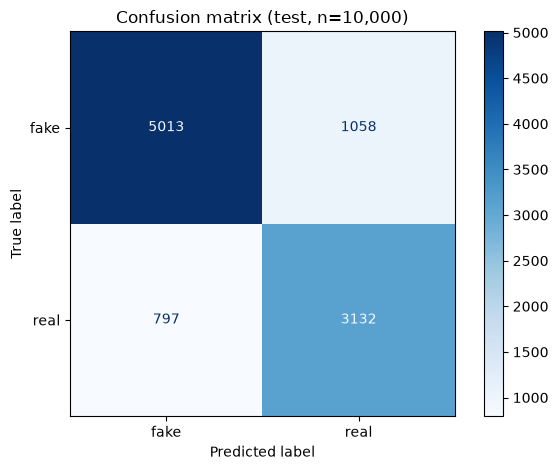

In [13]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["fake", "real"]).plot(cmap="Blues", values_format="d")  # eilutes = tikra klase, stulpeliai = spejimas; istrizaine = teisingi atsakymai
plt.title("Confusion matrix (test, n=10,000)"); plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=120); plt.show()

## 6. Most informative words
Positive coefficients push towards **real**, negative towards **fake**.

In [14]:
names = model.named_steps["features"].get_feature_names_out()  # vardai su prefiksu: title__zodis arba meta__stulpelis
coef = pd.Series(model.named_steps["clf"].coef_[0], index=names)  # teigiamas svoris stumia link real, neigiamas link fake
print("Metadata coefficients:"); print(coef[coef.index.str.startswith("meta__")].round(3))  # svoriai palyginami tarpusavyje, nes skaiciai standartizuoti
words = coef[coef.index.str.startswith("title__")].rename(lambda s: s.removeprefix("title__"))  # paliekam tik zodzius ir nuimam title__ prefiksa
top = pd.DataFrame({"fake": words.nsmallest(15).index, "fake_coef": words.nsmallest(15).values.round(2),  # is ju matosi, ko modelis is tikruju ismoko
                    "real": words.nlargest(15).index, "real_coef": words.nlargest(15).values.round(2)})
top

Metadata coefficients:
meta__score          -0.212
meta__num_comments    0.768
meta__upvote_ratio   -0.643
dtype: float64


,fake,fake_coef,real,real_coef
0,circa,-5.35,police,5.15
1,poster,-4.06,sign,4.59
2,discussions,-3.86,yearold,4.02
3,cutouts,-3.84,says,3.85
4,available,-2.89,cancer,3.61
5,mrw,-2.88,homeless,3.47
6,soviet,-2.79,restaurant,3.38
7,dont,-2.60,store,3.21
8,happy,-2.57,growing,3.11
9,imgur,-2.49,court,3.11


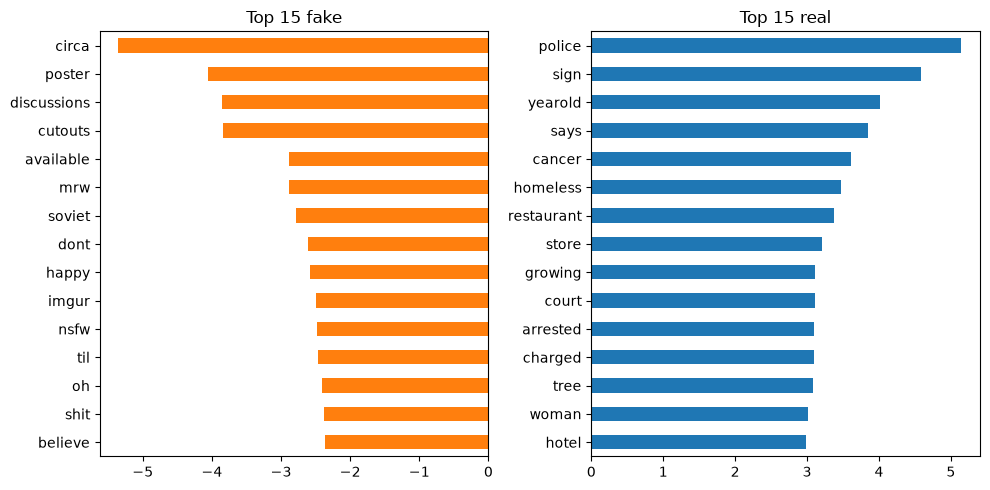

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
words.nsmallest(15).sort_values(ascending=False).plot.barh(ax=axes[0], color="tab:orange", title="Top 15 fake")
words.nlargest(15).sort_values().plot.barh(ax=axes[1], color="tab:blue", title="Top 15 real")
plt.tight_layout(); plt.savefig(FIG / "top_words.png", dpi=120); plt.show()

## 7. Save the pipeline
Load with `joblib.load("models/logreg_tfidf.joblib")` and call `.predict()` on a DataFrame with the four feature columns.

In [16]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(model, "../models/logreg_tfidf.joblib")  # saugom visa pipeline, ne tik modeli: naujai antrastei nereikes kartoti paruosimo zingsniu
assert (joblib.load("../models/logreg_tfidf.joblib").predict(X_test) == pred).all()  # is failo ikeltas modelis turi duoti lygiai tuos pacius spejimus